# Ride-time prior from drive time (Google or OpenRouteService)

Model: ride $R = \kappa \cdot T_{\text{drive}}(o, d, t) \cdot e^{\eta}$ (+ optional fixed overhead). $\kappa$ = shared-ride factor, calibrated so EBP-like trips (avg 11.43 mi) average EBP's 48.9-min ride; $\eta \sim \mathcal{N}(0, s^2)$ with $s$ from NYC actual/scheduled ride time plus an assumed extra term.

**Drive-time provider (picked automatically):**
1. `GOOGLE_MAPS_KEY` set → Google Routes API, traffic-aware, future departures. First run ≈ 900 elements (within Google's monthly free allowance; set a budget alert).
2. else `ORS_API_KEY` set → OpenRouteService, free (2,000 directions / 500 matrix requests per day), real roads but **no traffic**: same drive time all day. First run = 2 requests.
3. else → rough offline fallback so the notebook runs; numbers not meaningful.

Results are cached in `drive_cache.json` (per provider).

### 1. Imports & constants

In [26]:
import os, json, hashlib, urllib.request
from datetime import date, datetime, timedelta
from zoneinfo import ZoneInfo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

from dotenv import load_dotenv
load_dotenv()  # reads .env from the current working directory and its parents

TZ = ZoneInfo("America/Los_Angeles")
GOOGLE_KEY = os.environ.get("GOOGLE_MAPS_KEY")          # Google Routes API (traffic-aware, future departures)
ORS_KEY = os.environ.get("ORS_API_KEY")                  # OpenRouteService (free, no traffic) if no Google key
CACHE_PATH = "drive_cache.json"                          # Google results are cached here (saves money)

# East Bay Paratransit, Jul '25–Apr '26 (EBPAC packet, July 7, 2026)
EBP_AVG_RIDE_MIN = 48.9
EBP_AVG_TRIP_MI = 11.43

S_RHO = 0.33     # PASTE from ride_time.ipynb (pooled spread of NYC actual/scheduled ride time)
S_EXTRA = 0.15   # ASSUMPTION: extra spread because we don't know the van's manifest in advance
S_RIDE = np.sqrt(S_RHO**2 + S_EXTRA**2)
OVERHEAD_MIN = 0.0   # ASSUMPTION: fixed minutes per ride (boarding, securement). 0 -> pure factor model

BLUE, ORANGE, GRAY, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#a3a29c", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
PROVIDER = "google" if GOOGLE_KEY else "ors" if ORS_KEY else "offline"
print({"google": "Using Google Routes API (traffic-aware)",
       "ors": "Using OpenRouteService (free, typical road speeds, NO traffic -> same drive time all day)",
       "offline": "No key found -> rough offline fallback (numbers not meaningful)"}[PROVIDER])

Using Google Routes API (traffic-aware)


### 2. Drive times: Google Routes API (traffic-aware, future departures), cached; rough fallback offline

In [27]:
def _cache():
    try:
        return json.load(open(CACHE_PATH))
    except (FileNotFoundError, json.JSONDecodeError):
        return {}

_CACHE = _cache()

def _key(o, d, t_iso):
    return hashlib.md5(json.dumps([round(o[0], 5), round(o[1], 5), round(d[0], 5),
                                   round(d[1], 5), t_iso]).encode()).hexdigest()

def haversine_mi(o, d):
    lat1, lon1, lat2, lon2 = map(np.radians, (o[0], o[1], d[0], d[1]))
    a = np.sin((lat2 - lat1) / 2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2)**2
    return 3958.8 * 2 * np.arcsin(np.sqrt(a))

def _fallback(o, d, t_iso):
    """ROUGH offline stand-in: straight-line x 1.3 road factor, speed dips at rush hour. Not for real use."""
    miles = 1.3 * haversine_mi(o, d)
    h = datetime.fromisoformat(t_iso).hour + datetime.fromisoformat(t_iso).minute / 60
    rush = np.exp(-((h - 8.0) / 1.2)**2) + np.exp(-((h - 17.0) / 1.5)**2)
    mph = 28 - 10 * rush - 6 * np.exp(-miles / 4)            # short trips = slower streets
    return 60 * miles / mph, miles

def _google_matrix(origins, dests, t_iso):
    body = {"origins": [{"waypoint": {"location": {"latLng": {"latitude": o[0], "longitude": o[1]}}}} for o in origins],
            "destinations": [{"waypoint": {"location": {"latLng": {"latitude": d[0], "longitude": d[1]}}}} for d in dests],
            "travelMode": "DRIVE", "routingPreference": "TRAFFIC_AWARE", "departureTime": t_iso}
    req = urllib.request.Request(
        "https://routes.googleapis.com/distanceMatrix/v2:computeRouteMatrix", data=json.dumps(body).encode(),
        headers={"Content-Type": "application/json", "X-Goog-Api-Key": GOOGLE_KEY,
                 "X-Goog-FieldMask": "originIndex,destinationIndex,duration,distanceMeters,condition"})
    return json.load(urllib.request.urlopen(req))

def _ors_matrix(origins, dests):
    """OpenRouteService matrix: durations (min) and distances (mi) for all origin x destination pairs."""
    locs = [[o[1], o[0]] for o in origins] + [[d[1], d[0]] for d in dests]      # ORS wants [lng, lat]
    body = {"locations": locs, "sources": list(range(len(origins))),
            "destinations": list(range(len(origins), len(locs))),
            "metrics": ["duration", "distance"], "units": "mi"}
    req = urllib.request.Request(
        "https://api.openrouteservice.org/v2/matrix/driving-car", data=json.dumps(body).encode(),
        headers={"Content-Type": "application/json", "Authorization": ORS_KEY})
    res = json.load(urllib.request.urlopen(req))
    to_arr = lambda m: np.array([[np.nan if v is None else v for v in row] for row in m], float)
    return to_arr(res["durations"]) / 60, to_arr(res["distances"])

def drive_matrix(origins, dests, t_iso):
    """Drive minutes and miles for every origin x destination at departure t_iso.
    Providers bill/limit per element or request, so we only ever request full matrices we actually use."""
    t_key = t_iso if PROVIDER == "google" else "static"      # ORS/offline have no traffic -> time-independent
    O, D = len(origins), len(dests)
    mins, miles = np.full((O, D), np.nan), np.full((O, D), np.nan)
    missing = False
    for i, o in enumerate(origins):
        for j, d in enumerate(dests):
            k = _key(o, d, t_key) + PROVIDER
            if k in _CACHE:
                mins[i, j], miles[i, j] = _CACHE[k]
            elif PROVIDER == "offline":
                mins[i, j], miles[i, j] = _fallback(o, d, t_iso)
            else:
                missing = True
    if missing and PROVIDER == "google":
        assert O * D <= 625, "Google allows at most 625 elements per traffic-aware matrix request"
        for el in _google_matrix(origins, dests, t_iso):
            if el.get("condition") != "ROUTE_EXISTS":
                continue
            i, j = el.get("originIndex", 0), el.get("destinationIndex", 0)
            mins[i, j] = float(el["duration"].rstrip("s")) / 60
            miles[i, j] = el.get("distanceMeters", 0) / 1609.34
    elif missing and PROVIDER == "ors":
        assert O + D <= 3500, "ORS allows at most 3,500 locations per matrix request"
        mins, miles = _ors_matrix(origins, dests)
    if missing:
        for i, o in enumerate(origins):
            for j, d in enumerate(dests):
                if not np.isnan(mins[i, j]):
                    _CACHE[_key(o, d, t_key) + PROVIDER] = [mins[i, j], miles[i, j]]
        json.dump(_CACHE, open(CACHE_PATH, "w"))
    return mins, miles

def next_weekday_iso(weekday, hour, minute=0):
    """Next occurrence (future) of weekday (0=Mon) at local hour:minute, ISO with the correct UTC offset."""
    today = datetime.now(TZ).date()
    days = (weekday - today.weekday()) % 7 or 7
    dt = datetime.combine(today + timedelta(days=days), datetime.min.time()).replace(
        hour=hour, minute=minute, tzinfo=TZ)
    return dt.isoformat()

### 3. Sample plausible EBP trips (homes near transit -> clinics/BART/etc.)

In [28]:
# Anchors: BART stations across EBP's area (approximate coordinates); trips start/end near them.
ANCHORS = {
    "Richmond": (37.9369, -122.3533), "El Cerrito del Norte": (37.9252, -122.3170),
    "North Berkeley": (37.8740, -122.2834), "Downtown Berkeley": (37.8701, -122.2681),
    "Ashby": (37.8529, -122.2700), "Rockridge": (37.8445, -122.2514), "MacArthur": (37.8290, -122.2671),
    "19th St Oakland": (37.8080, -122.2689), "Lake Merritt": (37.7975, -122.2654),
    "Fruitvale": (37.7748, -122.2241), "Coliseum": (37.7537, -122.1969), "San Leandro": (37.7219, -122.1609),
    "Bay Fair": (37.6969, -122.1265), "Castro Valley": (37.6907, -122.0758), "Hayward": (37.6699, -122.0870),
    "South Hayward": (37.6345, -122.0572), "Union City": (37.5908, -122.0174), "Fremont": (37.5574, -121.9764),
}
rng = np.random.default_rng(42)
names = list(ANCHORS)

def jitter(p, km=1.2):                                         # EBP serves 3/4 mi around routes -> ~1 km spread
    dlat, dlon = rng.normal(0, km / 111, 2) / np.array([1, np.cos(np.radians(p[0]))])
    return (p[0] + dlat, p[1] + dlon)

# Trip ends near random anchors. Every origin x destination pair is used (12 x 10 = 120 trips),
# so each Google request returns only elements we need. Trip lengths are matched to EBP in cell 5.
ORIGINS = [jitter(ANCHORS[n]) for n in rng.choice(names, 12)]
DESTS = [jitter(ANCHORS[n]) for n in rng.choice(names, 10)]
print(f"{len(ORIGINS)} origins x {len(DESTS)} destinations = {len(ORIGINS) * len(DESTS)} trips")

12 origins x 10 destinations = 120 trips


### 4. Query drive times across a weekday (cached; 7 requests x 120 elements on first run)

In [29]:
HOURS = [7, 9, 11, 13, 15, 17, 19]
DAY = 3                                                        # Thursday
rows = []
for h in HOURS:
    mins, miles = drive_matrix(ORIGINS, DESTS, next_weekday_iso(DAY, h))   # one request per hour (120 elements)
    for i in range(len(ORIGINS)):
        for j in range(len(DESTS)):
            rows.append(dict(pair=i * len(DESTS) + j, hour=h, drive_min=mins[i, j], miles=miles[i, j]))
drv = pd.DataFrame(rows).dropna()
drv = drv[drv.miles > 0.5]                                     # drop near-identical start/end points
print(drv.groupby("hour")[["drive_min", "miles"]].mean().round(1))

      drive_min  miles
hour                  
7          27.0   15.5
9          29.0   15.7
11         25.2   15.4
13         26.1   15.4
15         30.1   15.4
17         33.6   15.3
19         23.7   15.4


### 5. Calibrate the shared-ride factor kappa to EBP's 48.9 min average ride

In [30]:
# Reweight sampled trips so their average road distance is exactly EBP's 11.43 mi (exponential tilting)
mi_by_pair = drv.groupby("pair").miles.mean()
def tilt(lam):
    w_ = np.exp(lam * mi_by_pair.to_numpy()); return w_ / w_.sum()
lam = optimize.brentq(lambda l: tilt(l) @ mi_by_pair.to_numpy() - EBP_AVG_TRIP_MI, -2, 2)
pair_w = pd.Series(tilt(lam), index=mi_by_pair.index)
drv["w"] = drv.pair.map(pair_w) / len(HOURS)                   # equal weight per departure hour

mean_drive = np.average(drv.drive_min, weights=drv.w)
KAPPA = (EBP_AVG_RIDE_MIN - OVERHEAD_MIN) / mean_drive          # matches the MEAN ride (see ride_prior_drive)
print(f"weighted mean distance {np.average(drv.miles, weights=drv.w):.2f} mi, "
      f"mean direct drive {mean_drive:.1f} min  ->  kappa = {KAPPA:.2f}")

def ride_prior_drive(drive_min, kappa=KAPPA, s=S_RIDE, overhead=OVERHEAD_MIN):
    """Lognormal ride prior (min). Mean ride = overhead + kappa * drive; median = mean * exp(-s^2/2)."""
    mean = overhead + kappa * np.asarray(drive_min, float)
    return stats.lognorm(s, scale=mean * np.exp(-s**2 / 2))

# Save the calibrated ride prior for other notebooks (booking_advice.ipynb)
json.dump({"KAPPA": float(KAPPA), "S_RIDE": float(S_RIDE), "OVERHEAD_MIN": float(OVERHEAD_MIN),
           "PROVIDER": PROVIDER}, open("ride_params.json", "w"), indent=1)
print("saved ride_params.json")

weighted mean distance 11.43 mi, mean direct drive 22.0 min  ->  kappa = 2.23
saved ride_params.json


### 6. Why drive time beats mileage: same distance, very different drives

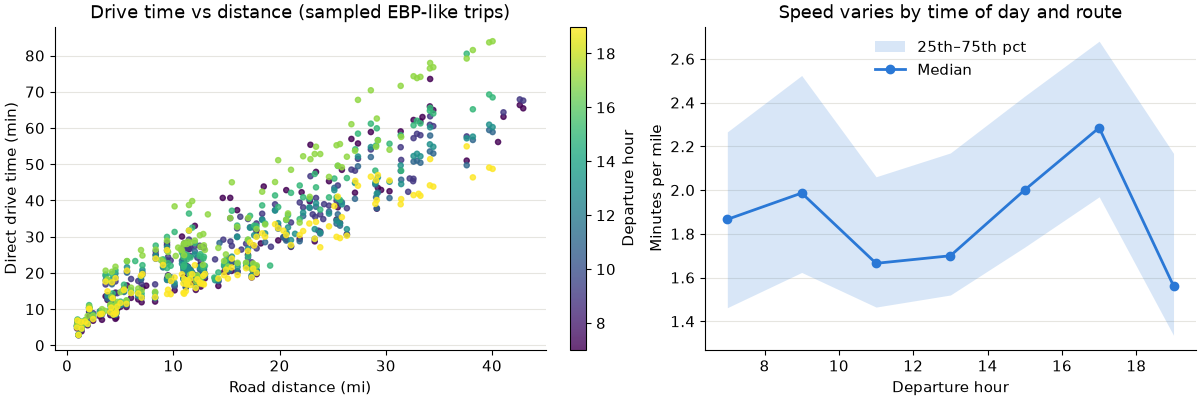

In [31]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
sc = a1.scatter(drv.miles, drv.drive_min, c=drv.hour, cmap="viridis", s=14, alpha=0.8)
fig.colorbar(sc, ax=a1, label="Departure hour")
a1.set(xlabel="Road distance (mi)", ylabel="Direct drive time (min)",
       title="Drive time vs distance (sampled EBP-like trips)")
per_mile = drv.assign(min_per_mi=drv.drive_min / drv.miles).groupby("hour").min_per_mi.describe()
a2.fill_between(per_mile.index, per_mile["25%"], per_mile["75%"], color=BLUE, alpha=0.18, lw=0, label="25th–75th pct")
a2.plot(per_mile.index, per_mile["50%"], "o-", color=BLUE, lw=2, label="Median")
a2.set(xlabel="Departure hour", ylabel="Minutes per mile", title="Speed varies by time of day and route")
a2.legend(frameon=False)
for ax in (a1, a2):
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

### 7. One trip across the day: ride prior from drive time (smooth slider; needs ipympl)

In [32]:
# With OpenRouteService the drive time is the same all day (no traffic), so the curve is flat.
%matplotlib widget
import ipywidgets as widgets

TRIP = (jitter(ANCHORS["Hayward"]), (37.7990, -122.2312))      # example: near Hayward BART -> Highland Hospital area (approx.)
t_steps = np.arange(6.0, 21.01, 0.25)                           # every 15 min (61 one-element requests, cached)
trip_drive = np.array([drive_matrix([TRIP[0]], [TRIP[1]], next_weekday_iso(DAY, int(t), int(round(t % 1 * 60))))[0][0, 0]
                       for t in t_steps])
priors = [ride_prior_drive(dm) for dm in trip_drive]
xr = np.linspace(0, max(p.ppf(0.995) for p in priors), 600)
ymax = max(p.pdf(xr).max() for p in priors) * 1.15

def hhmm(t):
    return f"{int(t):02d}:{int(round(t % 1 * 60)):02d}"

plt.ioff()
fig, (b1, b2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
fig.canvas.header_visible = False
pdf_line, = b1.plot(xr, np.zeros_like(xr), color=BLUE, lw=2)
drive_line = b1.axvline(0, color=ORANGE, lw=1.5, ls="--", label="Direct drive (Google)")
q_lines = [b1.axvline(0, color=MUTED, lw=1, ls=":") for _ in range(2)]
q_texts = [b1.text(0, 0, "", color=INK, fontsize=9) for _ in range(2)]
b1.set(xlim=(0, xr[-1]), ylim=(0, ymax), xlabel="Ride time (min)", ylabel="Density")
b1.legend(frameon=False, loc="upper right")
title = b1.set_title("", loc="left", color=INK, fontsize=11)

b2.fill_between(t_steps, [p.ppf(0.1) for p in priors], [p.ppf(0.9) for p in priors],
                color=BLUE, alpha=0.18, lw=0, label="Ride 10th–90th pct")
b2.plot(t_steps, [p.median() for p in priors], color=BLUE, lw=2, label="Ride median")
b2.plot(t_steps, trip_drive, color=ORANGE, lw=1.5, ls="--", label="Direct drive")
dot, = b2.plot([], [], "o", ms=10, color=BLUE, mec="white", mew=2)
b2.set(xlim=(t_steps[0], t_steps[-1]), xticks=range(6, 22, 2), xlabel="Departure time",
       ylabel="Minutes", title="This trip across a weekday")
b2.legend(frameon=False, loc="upper left", fontsize=9)
for ax in (b1, b2):
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)

def update(t):
    i = int(np.argmin(np.abs(t_steps - t)))
    p, dm = priors[i], trip_drive[i]
    pdf_line.set_ydata(p.pdf(xr))
    drive_line.set_xdata([dm, dm])
    for line, txt, (q_, lab) in zip(q_lines, q_texts, [(0.5, "median"), (0.9, "90th")]):
        v = p.ppf(q_)
        line.set_xdata([v, v]); txt.set_position((v + 1, ymax * 0.85)); txt.set_text(f"{lab}\n{v:.0f} min")
    title.set_text(f"Departing {hhmm(t_steps[i])}: drive {dm:.0f} min, ride mean {p.mean():.0f} min")
    dot.set_data([t_steps[i]], [p.median()])
    fig.canvas.draw_idle()

slider = widgets.FloatSlider(value=13.0, min=t_steps[0], max=t_steps[-1], step=0.25, description="Depart",
                             readout=False, continuous_update=True, layout=widgets.Layout(width="60%"))
label = widgets.Label(hhmm(slider.value))
def on_change(ch):
    update(ch["new"]); label.value = hhmm(t_steps[int(np.argmin(np.abs(t_steps - ch["new"])))])
slider.observe(on_change, names="value")
update(slider.value)
display(widgets.VBox([widgets.HBox([slider, label]), fig.canvas]))

### 8. Putting it together: P(arrive on time) = pickup prior + ride prior (1-D integral)

In [33]:
# Pickup prior from ebp_prior.ipynb: log(L + C) ~ N(pickup_mean, pickup_sd^2). Paste/import those values.
C_EARLY = 5.0

def p_on_time(appt, window_start, drive_min, pickup_mean, pickup_sd, now=None, m=2000):
    """Times in hours. Average of F_ride(D - L) over the (conditional) pickup distribution."""
    D = (appt - window_start) * 60
    tail = 1.0
    if now is not None:
        waited = max((now - window_start) * 60, -C_EARLY + 0.01)
        tail = stats.norm.sf((np.log(waited + C_EARLY) - pickup_mean) / pickup_sd)
    u = (np.arange(m) + 0.5) / m
    L = np.maximum(np.exp(pickup_mean + pickup_sd * stats.norm.isf(u * tail)) - C_EARLY, 0)
    return np.mean(ride_prior_drive(drive_min).cdf(D - L))

# Example: 2:00 appointment, 1:00 window, Google drive at 1:15 for the example trip
dm_115 = trip_drive[np.argmin(np.abs(t_steps - 13.25))]
for ws in (12.5, 12.75, 13.0):
    print(f"window {hhmm(ws)}: P(on time) = {p_on_time(14.0, ws, dm_115, 2.62, 0.588):.2f}")
print("window 13:00, still waiting at 13:20:", round(p_on_time(14.0, 13.0, dm_115, 2.62, 0.588, now=13 + 20/60), 2))

window 12:30: P(on time) = 0.90
window 12:45: P(on time) = 0.77
window 13:00: P(on time) = 0.54
window 13:00, still waiting at 13:20: 0.16


### 9. Prototype: a detour term so short rides get a real tail (not yet in `ride.py`)

The factor model scales all uncertainty with the drive. A 4.5-min drive averages a 10-min ride with a 99th percentile of 22 min, so once the rider is aboard with 35 min to spare the app says 100%. A shared van that stops for another rider adds 10–20 min however short the trip is.

Model: $R = \kappa_D \cdot T_{\text{drive}} \cdot e^{\eta} + B \cdot D$, with $B \sim \text{Bernoulli}(q)$ (an extra stop on the way) and $D$ lognormal (the minutes that stop adds). $q$ and $D$ are assumptions: none of our data shows individual stops.

Calibration, so the average trip doesn't change:
* $\kappa_D$ keeps EBP's 48.9-min mean ride: $\kappa_D = (48.9 - q\,E[D]) / \bar T_{\text{drive}}$.
* `S_EXTRA` was spread for the unknown manifest, which the detour term now carries. It is refit so the average trip's 90th percentile stays where it was.

This section only compares. It doesn't write `ride_params.json`.

kappa 2.227 -> 2.063, S_EXTRA 0.150 -> 0.152 (S_RIDE 0.362 -> 0.364)

              mean   p50    p90    p99   p999
drive model                                  
4.5   old     10.0   9.4   14.9   21.8   28.8
      detour  12.9  10.6   23.2   37.5   52.7
10.0  old     22.3  20.9   33.2   48.5   63.9
      detour  24.2  22.4   37.8   55.3   71.8
22.0  old     48.9  45.8   72.9  106.4  140.4
      detour  48.9  46.1   72.9  104.7  136.4
40.0  old     89.1  83.4  132.7  193.8  255.7
      detour  86.1  81.0  127.6  184.6  242.2


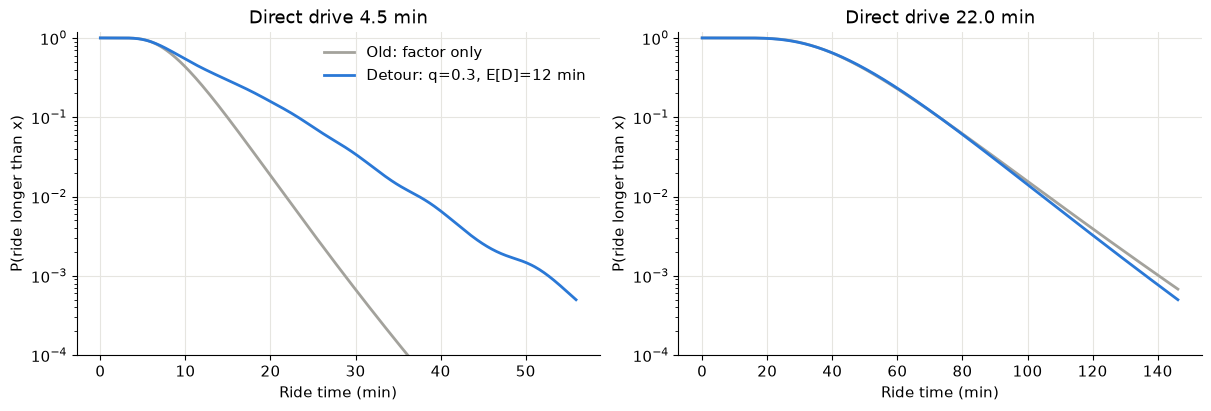

In [9]:
plt.close("all")                                               # static plots from here on
%matplotlib inline
Q_DETOUR = 0.30   # ASSUMPTION: share of rides with an extra stop (another rider's pickup or drop-off) on the way
D_MEAN = 12.0     # ASSUMPTION: mean minutes that stop adds (detour drive + boarding and securement)
S_D = 0.5         # ASSUMPTION: log-SD of those minutes (10th-90th pct ~ 6-20 min)
_Z, _W = np.polynomial.hermite_e.hermegauss(24)               # Gauss-Hermite nodes for E over log D
_W = _W / _W.sum()

class DetourRide:
    """base ride + B * D. Same calls as a frozen scipy dist: cdf, sf, ppf, isf, mean, median."""
    def __init__(self, base, q=Q_DETOUR, d_mean=D_MEAN, s_d=S_D):
        self.base, self.q, self.d_mean = base, q, d_mean
        self.D = d_mean * np.exp(s_d * _Z - s_d**2 / 2)        # nodes of D, mean d_mean
    def cdf(self, x):
        x = np.asarray(x, float)
        return (1 - self.q) * self.base.cdf(x) + self.q * (self.base.cdf(x[..., None] - self.D) @ _W)
    def sf(self, x):                                           # not 1 - cdf: keeps precision in the tail
        x = np.asarray(x, float)
        return (1 - self.q) * self.base.sf(x) + self.q * (self.base.sf(x[..., None] - self.D) @ _W)
    def _invert(self, f, p):
        hi = self.base.ppf(1 - 1e-12) + self.D.max()
        return np.vectorize(lambda p_: optimize.brentq(lambda x: float(f(x)) - p_, 0.0, hi, xtol=1e-6))(p)
    def ppf(self, p): return self._invert(self.cdf, p)
    def isf(self, p): return self._invert(lambda x: -self.sf(x), -np.asarray(p))
    def mean(self): return self.base.mean() + self.q * self.d_mean
    def median(self): return self.ppf(0.5)

def fit_detour(q=Q_DETOUR, d_mean=D_MEAN, s_d=S_D):
    """(kappa_D, s_ride_D, s_extra_D): mean ride stays 48.9, average trip's 90th pct stays put."""
    kappa = (EBP_AVG_RIDE_MIN - OVERHEAD_MIN - q * d_mean) / mean_drive
    p90_old = ride_prior_drive(mean_drive).ppf(0.9)
    gap = lambda se: DetourRide(ride_prior_drive(mean_drive, kappa, np.hypot(S_RHO, se)), q, d_mean, s_d).ppf(0.9) - p90_old
    se = 0.0 if gap(0) >= 0 else optimize.brentq(gap, 0, 1)
    return kappa, np.hypot(S_RHO, se), se

KAPPA_D, S_RIDE_D, S_EXTRA_D = fit_detour()

def ride_detour(drive_min, q=Q_DETOUR, d_mean=D_MEAN, s_d=S_D, kappa=None, s=None):
    return DetourRide(ride_prior_drive(drive_min, KAPPA_D if kappa is None else kappa,
                                       S_RIDE_D if s is None else s), q, d_mean, s_d)

print(f"kappa {KAPPA:.3f} -> {KAPPA_D:.3f}, S_EXTRA {S_EXTRA:.3f} -> {S_EXTRA_D:.3f} (S_RIDE {S_RIDE:.3f} -> {S_RIDE_D:.3f})\n")
rows = []
for dm in (4.5, 10, mean_drive, 40):
    for name, R in (("old", ride_prior_drive(dm)), ("detour", ride_detour(dm))):
        rows.append(dict(drive=round(dm, 1), model=name, mean=R.mean(), p50=R.median(),
                         p90=R.ppf(0.9), p99=R.ppf(0.99), p999=R.ppf(0.999)))
print(pd.DataFrame(rows).set_index(["drive", "model"]).astype(float).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, dm in zip(axes, (4.5, mean_drive)):
    xs = np.linspace(0, ride_detour(dm).ppf(0.9995), 300)
    ax.semilogy(xs, ride_prior_drive(dm).sf(xs), color=GRAY, lw=2, label="Old: factor only")
    ax.semilogy(xs, ride_detour(dm).sf(xs), color=BLUE, lw=2, label=f"Detour: q={Q_DETOUR}, E[D]={D_MEAN:.0f} min")
    ax.set(ylim=(1e-4, 1.2), xlabel="Ride time (min)", ylabel="P(ride longer than x)",
           title=f"Direct drive {dm:.1f} min")
    ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[0].legend(frameon=False)
plt.show()

### 10. The rider app's demo trip, before and after pickup

The 4.5-min trip: window 19:55, appointment 20:30, no grace, so 35 min from the window start. Before pickup, the lateness L comes from the backend's prior (`app.prediction.ontime`, the same numbers the app shows) and the arrival CDF is averaged over L as in `ontime.arrival_cdf`. After pickup, only the ride is uncertain.

check: backend 0.9352, here 0.9352

                             old  detour
before pickup              0.935   0.875
picked up at +0 min       0.9999  0.9860
picked up at +15 min      0.9816  0.8420
picked up at +25 min      0.5696  0.4591
picked up at +30 min      0.0412  0.0449

Latest window with P >= 0.93, minutes before the appointment:
  drive  4.5 min: old 35, detour 45
  drive 22.0 min: old 95, detour 95
  drive 40.0 min: old 160, detour 155


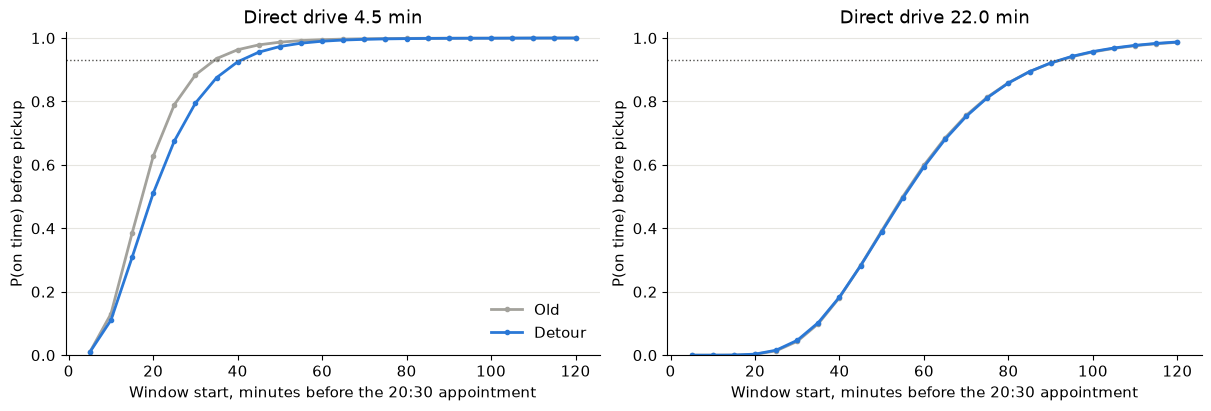

In [10]:
from app.prediction import ontime                              # the backend's pickup-lateness prior

W_DEMO, SLACK, DRIVE_DEMO = 19 * 60 + 55, 35.0, 4.5            # minutes since midnight, min, min
APPT = W_DEMO + SLACK

def p_before_pickup(R, w, appt=APPT):
    """P(arrival <= appt) for window start w, averaged over the backend's lateness quantiles."""
    return float(np.mean(R.cdf(appt - w - ontime.pickup_quantiles(w))))

old, new = ride_prior_drive(DRIVE_DEMO), ride_detour(DRIVE_DEMO)
print(f"check: backend {ontime.p_on_time(APPT, W_DEMO, DRIVE_DEMO):.4f}, here {p_before_pickup(old, W_DEMO):.4f}\n")
print(f"{'':24}{'old':>8}{'detour':>8}")
print(f"{'before pickup':24}{p_before_pickup(old, W_DEMO):8.3f}{p_before_pickup(new, W_DEMO):8.3f}")
for off in (0, 15, 25, 30):
    print(f"{f'picked up at +{off} min':24}{old.cdf(SLACK - off):8.4f}{new.cdf(SLACK - off):8.4f}")

def latest_window(R, appt=APPT, target=0.93, step=5, max_back=240):
    """Latest window start (5-min grid) with P(on time) >= target, as minutes before the appointment."""
    for w in np.arange((np.ceil(appt / step) - 1) * step, appt - max_back - 1e-9, -step):
        if p_before_pickup(R, w, appt) >= target:
            return appt - w

print(f"\nLatest window with P >= 0.93, minutes before the appointment:")
for dm in (DRIVE_DEMO, mean_drive, 40.0):
    print(f"  drive {dm:4.1f} min: old {latest_window(ride_prior_drive(dm)):.0f}, detour {latest_window(ride_detour(dm)):.0f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, dm in zip(axes, (DRIVE_DEMO, mean_drive)):
    back = np.arange(5, 121, 5.0)
    for name, R, col in (("Old", ride_prior_drive(dm), GRAY), ("Detour", ride_detour(dm), BLUE)):
        ax.plot(back, [p_before_pickup(R, APPT - b) for b in back], "o-", ms=3, color=col, lw=2, label=name)
    ax.axhline(0.93, color=MUTED, lw=1, ls=":")
    ax.set(xlabel="Window start, minutes before the 20:30 appointment", ylabel="P(on time) before pickup",
           title=f"Direct drive {dm:.1f} min", ylim=(0, 1.02))
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[0].legend(frameon=False, loc="lower right")
plt.show()

### 11. How much hangs on the assumptions

No data in the repo pins down $q$ or $E[D]$, so each pair below is refit ($\kappa_D$, `S_EXTRA`) and scored on the demo trip. "Window" is the latest window start with P ≥ 0.93, in minutes before the appointment (old model: shown in the first row).

In [11]:
rows = [dict(q=0.0, E_D=0.0, kappa=KAPPA, s_extra=S_EXTRA, before=p_before_pickup(old, W_DEMO),
             at_15=old.cdf(SLACK - 15), at_25=old.cdf(SLACK - 25), window=latest_window(old),
             window_avg_trip=latest_window(ride_prior_drive(mean_drive)))]
for q in (0.15, 0.30, 0.50):
    for d_mean in (8.0, 12.0, 18.0):
        k, s, se = fit_detour(q, d_mean)
        R = ride_detour(DRIVE_DEMO, q, d_mean, kappa=k, s=s)
        rows.append(dict(q=q, E_D=d_mean, kappa=k, s_extra=se, before=p_before_pickup(R, W_DEMO),
                         at_15=R.cdf(SLACK - 15), at_25=R.cdf(SLACK - 25), window=latest_window(R),
                         window_avg_trip=latest_window(ride_detour(mean_drive, q, d_mean, kappa=k, s=s))))
print(pd.DataFrame(rows).round(3).to_string(index=False))

   q  E_D  kappa  s_extra  before  at_15  at_25  window  window_avg_trip
0.00  0.0  2.227    0.150   0.935  0.982  0.570    35.0             95.0
0.15  8.0  2.172    0.156   0.919  0.943  0.513    40.0             95.0
0.15 12.0  2.145    0.146   0.904  0.910  0.520    40.0             95.0
0.15 18.0  2.104    0.105   0.878  0.876  0.535    45.0             95.0
0.30  8.0  2.118    0.167   0.905  0.907  0.451    40.0             95.0
0.30 12.0  2.063    0.152   0.875  0.842  0.459    45.0             95.0
0.30 18.0  1.981    0.067   0.825  0.773  0.487    50.0             95.0
0.50  8.0  2.045    0.188   0.886  0.864  0.358    40.0             95.0
0.50 12.0  1.954    0.179   0.839  0.760  0.360    45.0             95.0
0.50 18.0  1.817    0.097   0.758  0.645  0.389    50.0             95.0


### 12. In the van: the detour risk has to shrink as the ride goes on

`onboard.remaining_ride` rescales the ride by $f$, the share of it left. A fixed $q$ would keep a 30% chance of a 12-min stop until the van reaches the door. Treating stops as spread evenly along the ride gives $q_{\text{rem}} = 1 - (1 - q)^f$. Below, the van keeps its expected pace (elapsed $= (1 - f) \cdot \kappa \cdot T$) after a pickup at +15 and +25 min.

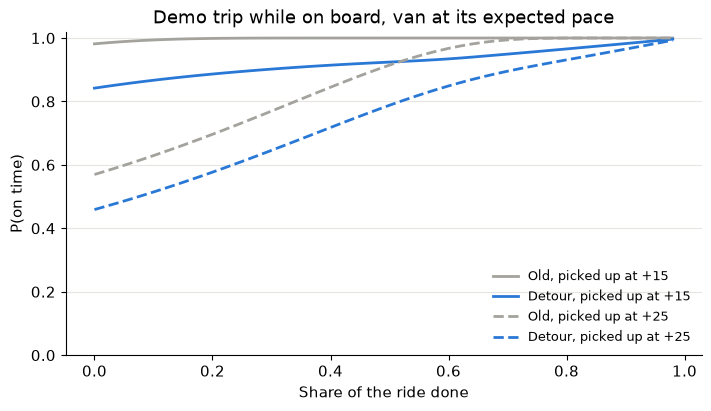

In [12]:
from app.prediction import onboard                             # the backend's in-van model (old)

def remaining_detour(drive_now, f, q=Q_DETOUR):
    """onboard.remaining_ride with the detour term: fewer stops left as the ride goes on."""
    kappa_rem = 1 + (KAPPA_D - 1) * f
    s_rem = S_RIDE_D * np.sqrt(max(f, 0.05))
    mean_rem = max(kappa_rem * drive_now + OVERHEAD_MIN * f, onboard.MIN_MEAN)
    return DetourRide(stats.lognorm(s_rem, scale=mean_rem * np.exp(-s_rem**2 / 2)), 1 - (1 - q) ** f)

fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
fs = np.linspace(1, 0.02, 50)
for off, ls in ((15, "-"), (25, "--")):
    left = SLACK - off - (1 - fs) * KAPPA * DRIVE_DEMO          # minutes to the appointment at share f left
    for name, fn, col in (("Old", onboard.remaining_ride, GRAY), ("Detour", remaining_detour, BLUE)):
        ax.plot(1 - fs, [fn(f * DRIVE_DEMO, f).cdf(t) for f, t in zip(fs, left)], ls, color=col, lw=2,
                label=f"{name}, picked up at +{off}")
ax.set(xlabel="Share of the ride done", ylabel="P(on time)", ylim=(0, 1.02),
       title="Demo trip while on board, van at its expected pace")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
plt.show()

### 13. Takeaways (q = 0.3, E[D] = 12 min)

* Short rides get a real tail. A 4.5-min drive's 99th percentile goes from 22 to 38 min. Picked up at the window start with 35 min to spare, the demo trip shows 98.6% instead of 99.99%.
* The average trip doesn't change by construction (mean 48.9 min, 90th percentile 72.9 min). Keeping that mean moves minutes from long trips to short ones: $\kappa$ drops from 2.23 to 2.06, so a 40-min drive's mean ride falls from 89 to 86 min and its 99th percentile from 194 to 185 min. Its latest 93% window moves 5 min later (160 to 155 min before the appointment), the risky direction, and nothing here checks that against data.
* Short trips need earlier pickups. The demo trip's latest 93% window moves from 35 to 45 min before the appointment, and its booked window drops from 93.5% to 87.5%. The average trip keeps its 95-min window.
* Picked up at +15, the demo trip shows 84%, below its 87.5% before pickup. That's expected: the van's median lateness at 19:55 is about 7 min, so boarding at +15 is worse than a typical pickup.
* In the van, the detour risk fades with the ride ($q_{\text{rem}} = 1 - (1 - q)^f$), so P still reaches ~100% at the door.
* The numbers depend on $q$ and $E[D]$, which no data here pins down: picked up at +15, the demo trip ranges from 65% to 94% across the table. Logged ride times of short trips (`record_completed_trip`) would.